## 1. Data Context and Source

**Dataset:** TripAdvisor Restaurants Info for 31 European Cities  
**Source:** [Kaggle – TripAdvisor Restaurants](https://www.kaggle.com/datasets/damienbeneschi/krakow-ta-restaurans-data-raw)

This project focuses on the 1,865 Edinburgh restaurant listings within the dataset published in 2018. Each row represents a restaurant and includes information such as cuisine, price band, customer rating and number of reviews.

### Why I chose this dataset

The dataset contains real restaurant information, a manageable number of records. It contains numerical and categorical data types which will support a range of visualisations and comparisons.

### Aim

Understand how restaurant prices and cuisine types relate to customer ratings in Edinburgh, to help inform restaurant pricing and menu decisions.

### Scope and limitations

The analysis describes a historical snapshot of TripAdvisor-listed restaurants. Price bands are categories rather than exact prices, and review counts do not represent sales or customer numbers. Missing information and differences in review counts will be considered when interpreting findings.

## 2. Import Dataset & Explore 

**Running this notebook:** Place `TA_restaurants_curated.csv` in the same folder as this notebook. Run the cells from top to bottom. Required packages: NumPy, Pandas, Matplotlib and Seaborn. The cleaned CSV is created during execution; the original source file is kept unchanged.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the original dataset
restaurants = pd.read_csv("TA_restaurants_curated.csv") 

restaurants.head()

,Unnamed: 0,Name,City,Cuisine Style,Ranking,Rating,Price Range,Number of Reviews,Reviews,URL_TA,ID_TA
0,0,Martine of Martine's Table,Amsterdam,"['French', 'Dutch', 'European']",1.0,5.0,$$ - $$$,136.0,"[['Just like home', 'A Warm Welcome to Wintry ...",/Restaurant_Review-g188590-d11752080-Reviews-M...,d11752080
1,1,De Silveren Spiegel,Amsterdam,"['Dutch', 'European', 'Vegetarian Friendly', '...",2.0,4.5,$$$$,812.0,"[['Great food and staff', 'just perfect'], ['0...",/Restaurant_Review-g188590-d693419-Reviews-De_...,d693419
2,2,La Rive,Amsterdam,"['Mediterranean', 'French', 'International', '...",3.0,4.5,$$$$,567.0,"[['Satisfaction', 'Delicious old school restau...",/Restaurant_Review-g188590-d696959-Reviews-La_...,d696959
3,3,Vinkeles,Amsterdam,"['French', 'European', 'International', 'Conte...",4.0,5.0,$$$$,564.0,"[['True five star dinner', 'A superb evening o...",/Restaurant_Review-g188590-d1239229-Reviews-Vi...,d1239229
4,4,Librije's Zusje Amsterdam,Amsterdam,"['Dutch', 'European', 'International', 'Vegeta...",5.0,4.5,$$$$,316.0,"[['Best meal.... EVER', 'super food experience...",/Restaurant_Review-g188590-d6864170-Reviews-Li...,d6864170


In [2]:
# Selecting Edinburgh restaurants and creating a separate DataFrame
edinburgh = restaurants[restaurants["City"] == "Edinburgh"].copy()

edinburgh.head()

,Unnamed: 0,Name,City,Cuisine Style,Ranking,Rating,Price Range,Number of Reviews,Reviews,URL_TA,ID_TA
31943,0,The Table,Edinburgh,"['European', 'British', 'Scottish']",1.0,5.0,$$$$,263.0,"[['Unforgettable', 'GROUP DINING EXPERIENCE DI...",/Restaurant_Review-g186525-d8479434-Reviews-Th...,d8479434
31944,1,Forage & Chatter,Edinburgh,"['European', 'British', 'Scottish', 'Vegetaria...",2.0,5.0,$$ - $$$,772.0,[['The pesto offered with the fresh dough bal....,/Restaurant_Review-g186525-d11722138-Reviews-F...,d11722138
31945,2,Aizle,Edinburgh,"['European', 'British', 'Scottish', 'Internati...",3.0,5.0,$$$$,642.0,"[['Beautiful Meal!', 'Is this my new favourite...",/Restaurant_Review-g186525-d6561056-Reviews-Ai...,d6561056
31946,3,Number One at The Balmoral,Edinburgh,"['European', 'British', 'Scottish', 'Vegetaria...",4.0,5.0,$$$$,1483.0,"[['A must if you are in Edinburgh!', 'Incredib...",/Restaurant_Review-g186525-d720180-Reviews-Num...,d720180
31947,4,Pickles,Edinburgh,"['Wine Bar', 'Scottish', 'Vegetarian Friendly']",5.0,5.0,$$ - $$$,810.0,"[['Wonderful', 'We saved the best until last']...",/Restaurant_Review-g186525-d4681770-Reviews-Pi...,d4681770


In [3]:
edinburgh.shape

(1865, 11)

In [4]:
# Check column names, data types and non-null counts
edinburgh.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1865 entries, 31943 to 33807
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         1865 non-null   int64  
 1   Name               1865 non-null   object 
 2   City               1865 non-null   object 
 3   Cuisine Style      1600 non-null   object 
 4   Ranking            1761 non-null   float64
 5   Rating             1760 non-null   float64
 6   Price Range        1429 non-null   object 
 7   Number of Reviews  1705 non-null   float64
 8   Reviews            1760 non-null   object 
 9   URL_TA             1865 non-null   object 
 10  ID_TA              1865 non-null   object 
dtypes: float64(3), int64(1), object(7)
memory usage: 174.8+ KB


In [5]:
# Count missing values in each column
edinburgh.isna().sum()

Unnamed: 0             0
Name                   0
City                   0
Cuisine Style        265
Ranking              104
Rating               105
Price Range          436
Number of Reviews    160
Reviews              105
URL_TA                 0
ID_TA                  0
dtype: int64

In [6]:
# Count completely repeated rows
edinburgh.duplicated().sum()

np.int64(0)

In [7]:
# Count repeated restaurant IDs
edinburgh["ID_TA"].duplicated().sum()

np.int64(0)

## 3. Data Cleaning & Transformation

In [8]:
# Create a separate copy for cleaning
edinburgh_clean = edinburgh.copy()

# Remove the old index column
edinburgh_clean = edinburgh_clean.drop(columns=["Unnamed: 0"])

# Restart the row index from 0
edinburgh_clean = edinburgh_clean.reset_index(drop=True)

edinburgh_clean.head()

,Name,City,Cuisine Style,Ranking,Rating,Price Range,Number of Reviews,Reviews,URL_TA,ID_TA
0,The Table,Edinburgh,"['European', 'British', 'Scottish']",1.0,5.0,$$$$,263.0,"[['Unforgettable', 'GROUP DINING EXPERIENCE DI...",/Restaurant_Review-g186525-d8479434-Reviews-Th...,d8479434
1,Forage & Chatter,Edinburgh,"['European', 'British', 'Scottish', 'Vegetaria...",2.0,5.0,$$ - $$$,772.0,[['The pesto offered with the fresh dough bal....,/Restaurant_Review-g186525-d11722138-Reviews-F...,d11722138
2,Aizle,Edinburgh,"['European', 'British', 'Scottish', 'Internati...",3.0,5.0,$$$$,642.0,"[['Beautiful Meal!', 'Is this my new favourite...",/Restaurant_Review-g186525-d6561056-Reviews-Ai...,d6561056
3,Number One at The Balmoral,Edinburgh,"['European', 'British', 'Scottish', 'Vegetaria...",4.0,5.0,$$$$,1483.0,"[['A must if you are in Edinburgh!', 'Incredib...",/Restaurant_Review-g186525-d720180-Reviews-Num...,d720180
4,Pickles,Edinburgh,"['Wine Bar', 'Scottish', 'Vegetarian Friendly']",5.0,5.0,$$ - $$$,810.0,"[['Wonderful', 'We saved the best until last']...",/Restaurant_Review-g186525-d4681770-Reviews-Pi...,d4681770


## Data Quality Checks

Checking that Ranking column contains numbers that are whole 

In [9]:
# Leave out missing values for this check
ranking_values = edinburgh_clean["Ranking"].dropna()

# Check whether every value is a whole number
(ranking_values % 1 == 0).all()

np.True_

Checking Number of Reviews for any values that are not whole numbers

In [10]:
# Leave out missing values for this check
review_values = edinburgh_clean["Number of Reviews"].dropna()

# Check whether every value is a whole number
(review_values % 1 == 0).all()

np.True_

In [11]:
# Convert to whole numbers while keeping missing values
edinburgh_clean["Ranking"] = edinburgh_clean["Ranking"].astype("Int64")
edinburgh_clean["Number of Reviews"] = edinburgh_clean["Number of Reviews"].astype("Int64")

# Check the updated types
edinburgh_clean[["Ranking", "Number of Reviews"]].dtypes

Ranking              Int64
Number of Reviews    Int64
dtype: object

## Handling Missing Values 

Inspecting "Rating" column

In [12]:
# Display restaurants with a missing rating
missing_ratings = edinburgh_clean[
    edinburgh_clean["Rating"].isna()
]

missing_ratings.head()

,Name,City,Cuisine Style,Ranking,Rating,Price Range,Number of Reviews,Reviews,URL_TA,ID_TA
1760,West Port Coffee,Edinburgh,"['Mediterranean', 'European', 'British', 'Midd...",1768,NaN,$,<NA>,NaN,/Restaurant_Review-g186525-d13084999-Reviews-W...,d13084999
1761,Tuscan Square,Edinburgh,"['Italian', 'British']",<NA>,NaN,$$$$,<NA>,NaN,/Restaurant_Review-g186525-d732443-Reviews-Tus...,d732443
1762,deli express,Edinburgh,['Cafe'],<NA>,NaN,NaN,<NA>,NaN,/Restaurant_Review-g186525-d794343-Reviews-Del...,d794343
1763,mitzi's,Edinburgh,NaN,<NA>,NaN,NaN,<NA>,NaN,/Restaurant_Review-g186525-d1317559-Reviews-Mi...,d1317559
1764,Mai Thai,Edinburgh,['Thai'],<NA>,NaN,$$ - $$$,<NA>,NaN,/Restaurant_Review-g186525-d1389124-Reviews-Ma...,d1389124


In [13]:
missing_ratings.shape[0]

105

### Missing Ratings

105 restaurants have no recorded rating. These values are kept missing rather than replaced with an assumed score. The restaurants remain in the main dataset but will be excluded from analyses that require ratings.

Inspecting the Number of Reviews column

In [14]:
# Display restaurants with missing review counts
missing_review_counts = edinburgh_clean[
    edinburgh_clean["Number of Reviews"].isna()
]

missing_review_counts.head()

,Name,City,Cuisine Style,Ranking,Rating,Price Range,Number of Reviews,Reviews,URL_TA,ID_TA
1177,Armstrong's Deli,Edinburgh,NaN,1178,5.0,NaN,<NA>,"[['The best stromboli in town'], ['06/21/2016']]",/Restaurant_Review-g186525-d5814884-Reviews-Ar...,d5814884
1178,Belhaven Beef,Edinburgh,NaN,1179,5.0,NaN,<NA>,[['Simply the best burgers and bangers in Edi....,/Restaurant_Review-g186525-d2146312-Reviews-Be...,d2146312
1180,Pizza Tree,Edinburgh,"['Italian', 'Pizza', 'Soups']",1181,5.0,$,<NA>,"[['Gorgeous pizza , Great Marco !'], ['03/27/2...",/Restaurant_Review-g186525-d12207455-Reviews-P...,d12207455
1182,Cafe Provencal,Edinburgh,NaN,1183,5.0,NaN,<NA>,"[['An Edinburgh delight'], ['04/14/2015']]",/Restaurant_Review-g186525-d5525540-Reviews-Ca...,d5525540
1183,Food Shack,Edinburgh,NaN,1184,5.0,NaN,<NA>,[['Amazing effort put into this little traile....,/Restaurant_Review-g186525-d8374350-Reviews-Fo...,d8374350


In [15]:
# Count these restaurants
missing_review_counts.shape[0]

160

Some have ratings and written reviews, so a missing count clearly does not mean zero reviews so this needs further investigation.

In [16]:
#Compare missing review counts with missing ratings
#Replace True and False with descriptive labels

missing_summary = pd.crosstab(
    edinburgh_clean["Number of Reviews"].isna(),
    edinburgh_clean["Rating"].isna()
)

missing_summary.index = ["Review count available", "Review count missing"]
missing_summary.columns = ["Rating available", "Rating missing"]

missing_summary

,Rating available,Rating missing
Review count available,1705,0
Review count missing,55,105


Of the 160 restaurants without a recorded review count, 55 still have a rating. A missing count therefore does not mean zero reviews. Counts remain missing, and comparisons requiring them use only known values.

Inspecting price range column

In [17]:
# Display restaurants with missing price ranges
missing_prices = edinburgh_clean[
    edinburgh_clean["Price Range"].isna()
]

missing_prices.head()

,Name,City,Cuisine Style,Ranking,Rating,Price Range,Number of Reviews,Reviews,URL_TA,ID_TA
23,Michael Neave's Kitchen and Whisky Bar,Edinburgh,"['European', 'British', 'Scottish', 'Vegetaria...",24,4.5,NaN,973,"[['Exceptional birthday meal.', 'Excellent foo...",/Restaurant_Review-g186525-d3242778-Reviews-Mi...,d3242778
221,Bramble Bar & Lounge,Edinburgh,NaN,222,4.5,NaN,347,"[['Good bar scene', 'So glad we found this pla...",/Restaurant_Review-g186525-d1722765-Reviews-Br...,d1722765
577,The Balmoral Bar,Edinburgh,"['Bar', 'Scottish', 'British']",578,4.0,NaN,342,"[['Nice place for a drink or two', 'Fantastic ...",/Restaurant_Review-g186525-d3604699-Reviews-Th...,d3604699
821,The Pastry Section,Edinburgh,NaN,822,5.0,NaN,10,[['Best coffee in Stockbridge if not Edinburg....,/Restaurant_Review-g186525-d12638779-Reviews-T...,d12638779
824,The Montebar,Edinburgh,"['Bar', 'Pub']",825,4.5,NaN,15,"[['Great Find', 'Full monty'], ['09/05/2017', ...",/Restaurant_Review-g186525-d11995699-Reviews-T...,d11995699


In [18]:
# Count missing price ranges
missing_prices.shape[0]

436

Missing price ranges were labelled "Unknown". These restaurants remain in the dataset but will be excluded from comparisons between known price bands.

In [19]:
# Label missing price ranges
edinburgh_clean["Price Range"] = edinburgh_clean["Price Range"].fillna("Unknown")

# Check the categories and counts
edinburgh_clean["Price Range"].value_counts(dropna=False)

Price Range
$$ - $$$    968
Unknown     436
$           415
$$$$         46
Name: count, dtype: int64

Inspecting 'Cuisine' column

In [20]:
# Count missing cuisine entries
edinburgh_clean["Cuisine Style"].isna().sum()

np.int64(265)

Missing cuisine information was labelled "Unknown" rather than assigning an assumed cuisine. These restaurants remain in the dataset.

In [21]:
# Label missing cuisine information
edinburgh_clean["Cuisine Style"] = edinburgh_clean["Cuisine Style"].fillna("Unknown")

# Check that no missing cuisine entries remain
edinburgh_clean["Cuisine Style"].isna().sum()

np.int64(0)

Checking for missing values throughout our dataset

In [22]:
# Review missing values after our changes
edinburgh_clean.isna().sum()

Name                   0
City                   0
Cuisine Style          0
Ranking              104
Rating               105
Price Range            0
Number of Reviews    160
Reviews              105
URL_TA                 0
ID_TA                  0
dtype: int64

### Missing-value decisions

- Missing price ranges and cuisines were labelled "Unknown".
- Missing rankings, ratings, review counts and review text were retained.
- Each analysis will exclude only records missing the information it needs and report the number included.
- No restaurants were removed during this step.

To make the price band column easier to read and understand I am going to add a descriptive label to it

In [23]:
# Replace price symbols with descriptive labels
edinburgh_clean["Price Range"] = edinburgh_clean["Price Range"].replace({
    "$": "Budget",
    "$$ - $$$": "Mid-range",
    "$$$$": "Expensive"
})

# Check the updated labels and counts
edinburgh_clean["Price Range"].value_counts()

Price Range
Mid-range    968
Unknown      436
Budget       415
Expensive     46
Name: count, dtype: int64

In [24]:
# Display the first five cuisine entries in full
edinburgh_clean["Cuisine Style"].head().tolist()

["['European', 'British', 'Scottish']", "['European', 'British', 'Scottish', 'Vegetarian Friendly', 'Vegan Options', 'Gluten Free Options']", "['European', 'British', 'Scottish', 'International', 'Vegetarian Friendly', 'Gluten Free Options']", "['European', 'British', 'Scottish', 'Vegetarian Friendly', 'Vegan Options', 'Gluten Free Options']", "['Wine Bar', 'Scottish', 'Vegetarian Friendly']"]

Cuisine information is stored as text. Converting it into a list of individual labels lets us compare cuisines separately.

In [25]:
# Remove the surrounding brackets
edinburgh_clean["Cuisine Labels"] = (
    edinburgh_clean["Cuisine Style"].str.strip("[]")
)

# Remove single quotation marks
edinburgh_clean["Cuisine Labels"] = (
    edinburgh_clean["Cuisine Labels"].str.replace("'", "", regex=False)
)

# Split the text into a list of labels
edinburgh_clean["Cuisine Labels"] = (
    edinburgh_clean["Cuisine Labels"].str.split(", ")
)

edinburgh_clean["Cuisine Labels"].head()

0                        [European, British, Scottish]
1    [European, British, Scottish, Vegetarian Frien...
2    [European, British, Scottish, International, V...
3    [European, British, Scottish, Vegetarian Frien...
4            [Wine Bar, Scottish, Vegetarian Friendly]
Name: Cuisine Labels, dtype: object

The entries are now lists of labels. dtype: object is expected because the column contains Python lists.

Next, I will inspect all the labels before deciding which to separate.

In [26]:
# Put each label on a separate row in a temporary Series
cuisine_labels = edinburgh_clean["Cuisine Labels"].explode() #.explode() lets us count individual labels

# Count each label
cuisine_labels.value_counts()

Cuisine Labels
Vegetarian Friendly    906
British                696
Gluten Free Options    627
Scottish               485
Vegan Options          471
                      ... 
Swiss                    1
Taiwanese                1
Canadian                 1
Ukrainian                1
Australian               1
Name: count, Length: 82, dtype: int64

82 distinct labels have been found but they mix cuisines, dietary options and venue types.

In [27]:
# Checking the final size and data types
edinburgh_clean.shape

(1865, 11)

In [28]:
edinburgh_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1865 entries, 0 to 1864
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Name               1865 non-null   object 
 1   City               1865 non-null   object 
 2   Cuisine Style      1865 non-null   object 
 3   Ranking            1761 non-null   Int64  
 4   Rating             1760 non-null   float64
 5   Price Range        1865 non-null   object 
 6   Number of Reviews  1705 non-null   Int64  
 7   Reviews            1760 non-null   object 
 8   URL_TA             1865 non-null   object 
 9   ID_TA              1865 non-null   object 
 10  Cuisine Labels     1865 non-null   object 
dtypes: Int64(2), float64(1), object(8)
memory usage: 164.0+ KB


### Cleaning and transformation summary

- No duplicate rows or restaurant IDs were found.
- Removed the old index column and reset the row index.
- Converted rankings and review counts to whole numbers, preserving missing values.
- Labelled missing cuisines and price bands as "Unknown".
- Replaced price symbols with descriptive labels.
- Created cuisine lists for analysing individual labels.
- Retained all 1,865 restaurants. Each analysis will use the records with the information it requires.

In [29]:
# Save the prepared dataset without an extra index column
edinburgh_clean.to_csv("edinburgh_restaurants_clean.csv", index=False)

## 4. Exploratory Data Analysis

Now I am going to explore my data to identify patterns and areas for further investigation.

### Analytical Questions

These questions explore pricing, cuisine, ranking and customer feedback. Restaurant and review counts help put the findings into context.

| Question / hypothesis | Business objective |
|---|---|
| **1. Do higher prices mean better ratings?** Higher price bands may not consistently outperform budget options. | Assess how price positioning relates to customer satisfaction. |
| **2. How do customer ratings vary across cuisines, and how much evidence supports the differences?** High averages may rely on limited feedback. | Identify cuisines worth investigating for menu planning. |
| **3. Among restaurants rated 4.5, how do review counts relate to Edinburgh’s TripAdvisor ranking positions?** The same displayed rating can accompany different rankings. | Explore how review counts accompany ranking differences. |
| **4. How do price bands vary across cafés, pubs and wine bars?** Venue types may occupy different price segments. | Identify relevant competitor groups for pricing comparisons. |
| **5. What do customers mention about food, service and value in review excerpts, and how do these themes differ between higher- and lower-rated restaurants?** Theme mentions may add context beyond numerical ratings. | Identify customer-experience themes to investigate when planning menus and service. |

These comparisons show associations, not cause and effect. Keyword matches identify theme mentions rather than positive or negative sentiment.

## Question 1: Do higher prices mean better ratings?

We’ll compare the average rating, median rating and number of rated restaurants in each known price band. The counts help us judge how much evidence supports each comparison.

In [30]:
# Exclude unknown prices and missing ratings for this comparison

price_comparison = edinburgh_clean[
    edinburgh_clean["Price Range"] != "Unknown"
].dropna(subset=["Rating"])

# Summarise ratings by price band
price_summary = price_comparison.groupby("Price Range")["Rating"].agg(
    ["count", "mean", "median"]
)

# Arrange price bands from lowest to highest
price_summary = price_summary.reindex(["Budget", "Mid-range", "Expensive"])

price_summary.round(2)

,count,mean,median
Price Range,,,
Budget,410,4.07,4.0
Mid-range,959,4.09,4.0
Expensive,44,4.44,4.5


### Finding: price bands and ratings

Expensive restaurants have higher average and median ratings. However, Budget and Mid-range ratings are nearly identical, so the results do not show a steady increase across every price band. The expensive group is much smaller.

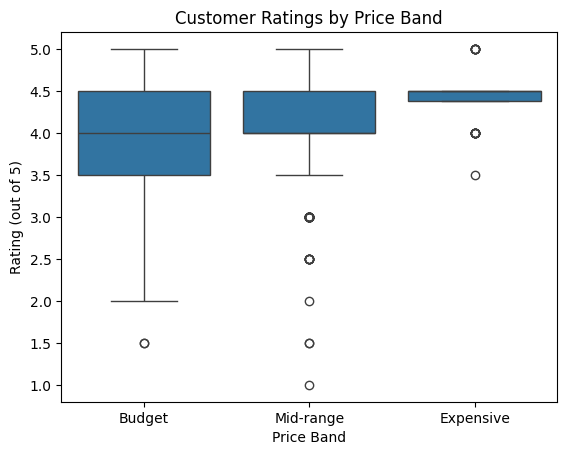

In [31]:
sns.boxplot(
    data=price_comparison,
    x="Price Range",
    y="Rating",
    order=["Budget", "Mid-range", "Expensive"]
)

plt.title("Customer Ratings by Price Band")
plt.xlabel("Price Band")
plt.ylabel("Rating (out of 5)")
plt.show()

### Key takeaway

Expensive restaurants tend to receive higher ratings, but all price bands include highly rated restaurants. Price alone does not guarantee a higher rating, and the expensive group is much smaller sample size (44 restaurants).

The circles indicate values outside the box plot’s usual whisker range—they are not automatically errors or records to remove.

## Question 2. How do customer ratings and reviews vary across cuisines, and which patterns could inform menu choices?

I will compare average and median ratings, the number of rated restaurants and median review counts. Review counts provide context rather than measuring demand. First, I will separate the cuisine labels and select common geographic cuisines.

In [32]:
# Keep restaurant details alongside each individual label
cuisine_data = edinburgh_clean.explode("Cuisine Labels")

# Display all labels and their counts
print(cuisine_data["Cuisine Labels"].value_counts().to_string())

Cuisine Labels
Vegetarian Friendly    906
British                696
Gluten Free Options    627
Scottish               485
Vegan Options          471
European               327
Bar                    322
Cafe                   316
Pub                    280
Unknown                265
Asian                  229
Fast Food              192
Italian                163
Pizza                  149
Indian                 131
Mediterranean           96
Chinese                 92
American                79
Soups                   68
Halal                   63
Seafood                 46
French                  44
International           41
Thai                    41
Middle Eastern          40
Gastropub               37
Healthy                 37
Japanese                36
Turkish                 36
Balti                   35
Contemporary            31
Wine Bar                30
Sushi                   30
Grill                   30
Mexican                 29
Bangladeshi             27
Steakhouse   

In [33]:
# Select the 10 most common geographic cuisines
selected_cuisines = [
    "British", "Scottish", "European", "Asian", "Italian",
    "Indian", "Mediterranean", "Chinese", "American", "French"
]

cuisine_comparison = cuisine_data[
    cuisine_data["Cuisine Labels"].isin(selected_cuisines)
]

In [34]:
# Summarise each cuisine
cuisine_summary = cuisine_comparison.groupby("Cuisine Labels").agg(
    rated_restaurants=("Rating", "count"),
    mean_rating=("Rating", "mean"),
    median_rating=("Rating", "median"),
    median_reviews=("Number of Reviews", "median"),
    known_review_counts=("Number of Reviews", "count")
)

cuisine_summary.sort_values("mean_rating", ascending=False).round(2)

,rated_restaurants,mean_rating,median_rating,median_reviews,known_review_counts
Cuisine Labels,,,,,
Mediterranean,95,4.34,4.5,216.5,94
French,41,4.33,4.5,445.0,41
European,322,4.27,4.5,311.0,322
Scottish,478,4.21,4.5,223.5,476
British,680,4.13,4.0,157.0,673
Indian,125,4.09,4.0,111.5,124
Asian,225,4.08,4.0,118.0,225
Italian,156,4.05,4.0,184.0,154
Chinese,88,3.79,4.0,41.0,87


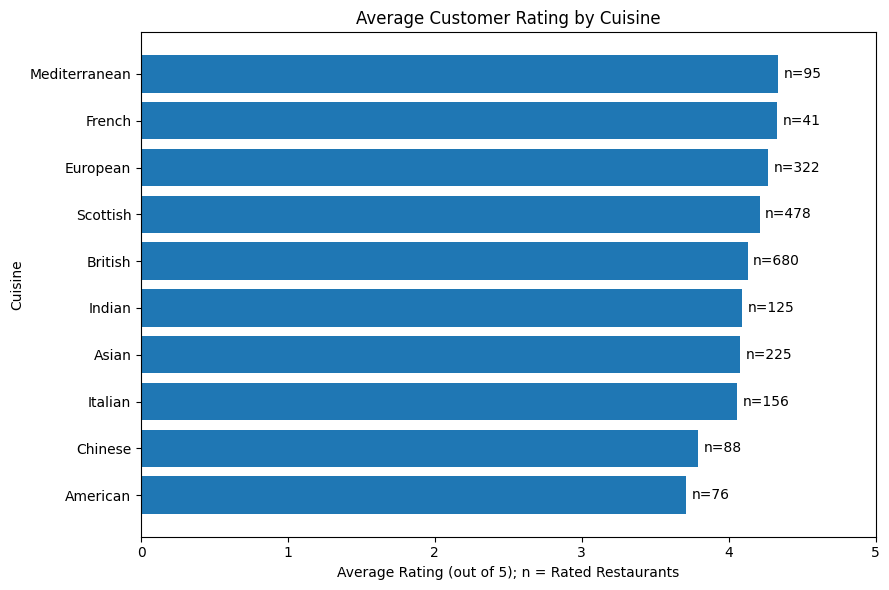

In [35]:
# Sort cuisines by average rating
chart_data = cuisine_summary.sort_values("mean_rating")

plt.figure(figsize=(9, 6))
bars = plt.barh(chart_data.index, chart_data["mean_rating"])

# Label each bar with its rated restaurant count
plt.bar_label(
    bars,
    labels=["n=" + str(n) for n in chart_data["rated_restaurants"]],
    padding=4
)

plt.title("Average Customer Rating by Cuisine")
plt.xlabel("Average Rating (out of 5); n = Rated Restaurants")
plt.ylabel("Cuisine")
plt.xlim(0, 5)
plt.tight_layout()
plt.show()

The bar chart compares average ratings and shows restaurant counts

Mediterranean and French have the highest average ratings, while European and Scottish show strong ratings across larger restaurant groups.

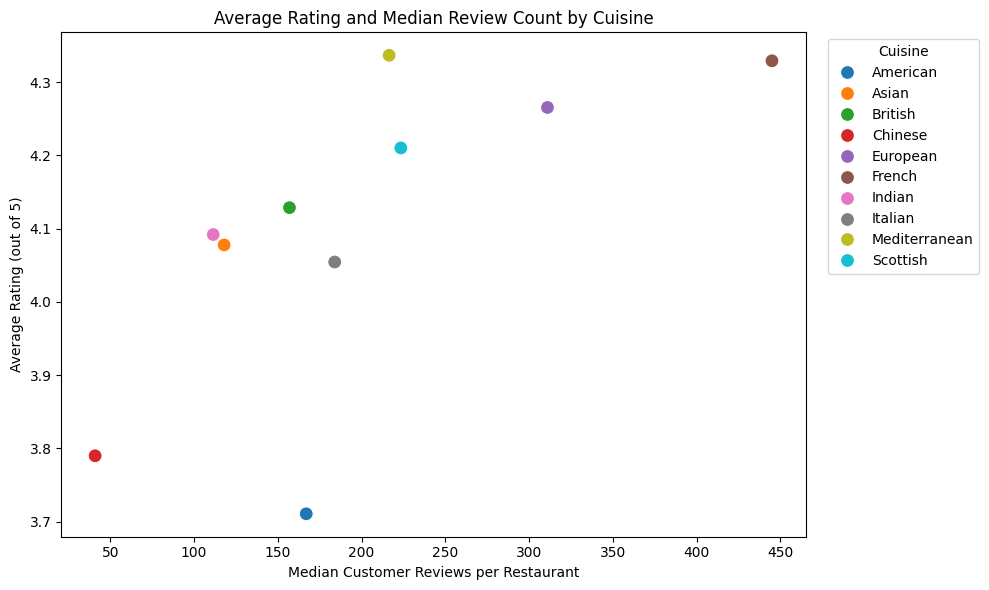

In [36]:
# Make cuisine names available as a column
scatter_data = cuisine_summary.reset_index()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=scatter_data,
    x="median_reviews",
    y="mean_rating",
    hue="Cuisine Labels",
    s=100
)

plt.title("Average Rating and Median Review Count by Cuisine")
plt.xlabel("Median Customer Reviews per Restaurant")
plt.ylabel("Average Rating (out of 5)")
plt.legend(title="Cuisine", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

French has the highest median review count. More reviews do not consistently mean higher ratings.


Ratings differ across cuisines. Mediterranean, French, European and Scottish merit further investigation for menu planning, but ratings alone cannot establish business potential.

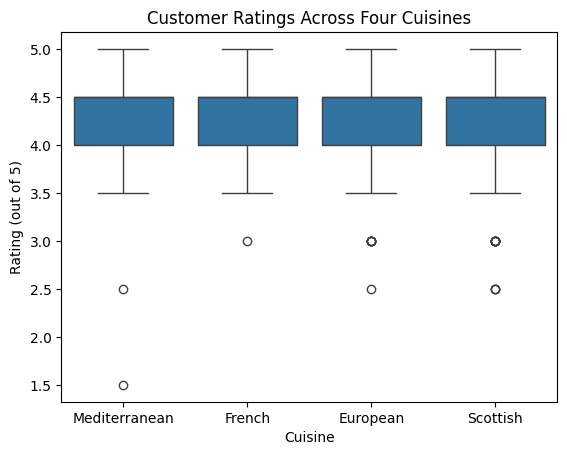

In [37]:
# Focus on the four cuisines identified
# Give each cuisine row a unique index
cuisine_plot = cuisine_comparison.reset_index(drop=True)

sns.boxplot(
    data=cuisine_plot,
    x="Cuisine Labels",
    y="Rating",
    order=["Mediterranean", "French", "European", "Scottish"]
)

plt.title("Customer Ratings Across Four Cuisines")
plt.xlabel("Cuisine")
plt.ylabel("Rating (out of 5)")
plt.show()

### Findings

All four cuisines have a median of 4.5, with the middle 50% of ratings between 4.0 and 4.5. Their similar distributions suggest no clear advantage for one cuisine, despite differences in averages.

### Key Takeaway

Mediterranean and French have the highest average ratings, but their rating distributions closely overlap with European and Scottish. 

French has more reviews per restaurant but a smaller restaurant sample.

These cuisines merit further investigation; the evidence does not identify a clear winner.

## Question 3. Among restaurants with the same customer rating, how does the number of reviews relate to their position in Edinburgh’s TripAdvisor rankings?

Now I will compare restaurants with the same customer rating to explore how review counts relate to their TripAdvisor ranking positions.

Rows missing a rating, ranking or review count are excluded from this comparison. We first count restaurants at each rating to select a group with enough data.

A lower ranking number means a better position.

In [38]:
# Keep rows with a rating, ranking and review count
rank_comparison = edinburgh_clean.dropna(
    subset=["Rating", "Ranking", "Number of Reviews"]
).copy()

In [39]:
# Count restaurants in each rating group
rank_comparison["Rating"].value_counts().sort_index()

Rating
1.0      1
1.5     10
2.0     15
2.5     43
3.0    100
3.5    264
4.0    532
4.5    581
5.0    159
Name: count, dtype: int64

4.5 is the largest rating group, with 581 restaurants. We’ll start there so every restaurant in the comparison has the same displayed rating.

In [40]:
# Select restaurants with a rating of 4.5
rating_45 = rank_comparison[
    rank_comparison["Rating"] == 4.5
].copy()

# Show the lowest, middle and highest values as whole numbers
rank_summary = rating_45[["Ranking", "Number of Reviews"]].agg(
    ["min", "median", "max"]
)

rank_summary.astype("Int64")

,Ranking,Number of Reviews
min,6,2
median,451,134
max,1620,5251


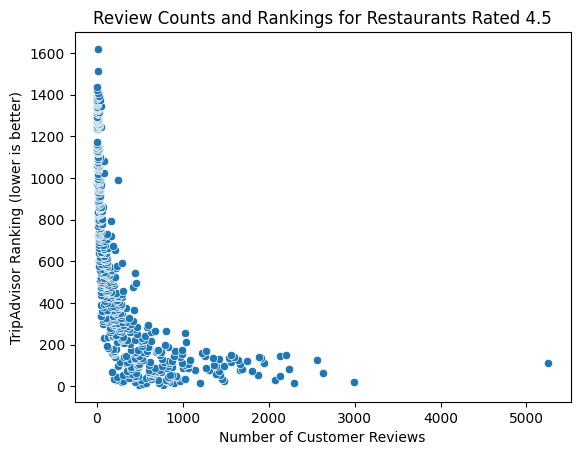

In [41]:
sns.scatterplot(
    data=rating_45,
    x="Number of Reviews",
    y="Ranking"
)

plt.title("Review Counts and Rankings for Restaurants Rated 4.5")
plt.xlabel("Number of Customer Reviews")
plt.ylabel("TripAdvisor Ranking (lower is better)")
plt.show()

Among restaurants rated 4.5, higher review counts generally accompany better ranking positions. The crowded points make low-review restaurants harder to compare.

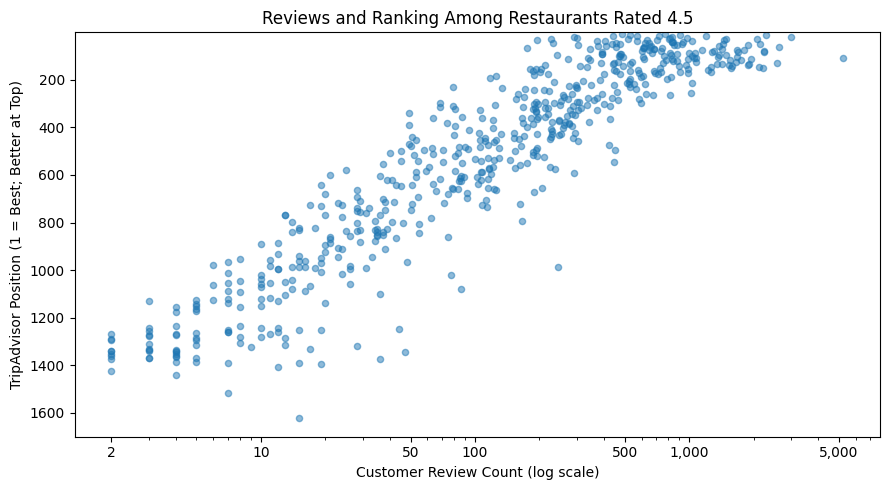

In [42]:
plt.figure(figsize=(9, 5))

plt.scatter(
    rating_45["Number of Reviews"],
    rating_45["Ranking"],
    alpha=0.5,
    s=20
)

plt.xscale("log")
plt.xticks([2, 10, 50, 100, 500, 1000, 5000],
           ["2", "10", "50", "100", "500", "1,000", "5,000"])
plt.ylim(1700, 1)

plt.title("Reviews and Ranking Among Restaurants Rated 4.5")
plt.xlabel("Customer Review Count (log scale)")
plt.ylabel("TripAdvisor Position (1 = Best; Better at Top)")
plt.tight_layout()
plt.show()


Revised scatter plot - The log scale reveals the pattern more clearly: restaurants with few reviews generally rank worse, while those with many reviews tend to rank better. Exceptions remain.

Across 581 restaurants with the same displayed rating, review counts are associated with ranking differences. Rating alone does not describe a restaurant’s position. This does not prove that additional reviews improve ranking, and findings apply only to the 4.5-rated group.

## Question 4. How do price bands vary across cafés, pubs and wine bars?

In [43]:
# Separate labels into rows and give each row a unique index

venue_data = edinburgh_clean.explode("Cuisine Labels").reset_index(drop=True)  # .explode()` repeats row indexes when a restaurant has several labels. Resetting the index gives each row a unique index and avoids alignment errors. No records were removed.

In [44]:
# Keep cafés, pubs and wine bars
venue_data = venue_data[
    venue_data["Cuisine Labels"].isin(["Cafe", "Pub", "Wine Bar"])
]

# Check the number in each group
venue_data["Cuisine Labels"].value_counts()

Cuisine Labels
Cafe        316
Pub         280
Wine Bar     30
Name: count, dtype: int64

In [45]:
# Compare venue types and price bands
venue_prices = pd.crosstab(
    venue_data["Cuisine Labels"],
    venue_data["Price Range"]
)

venue_prices

Price Range,Budget,Mid-range,Unknown
Cuisine Labels,,,
Cafe,158,111,47
Pub,56,207,17
Wine Bar,1,28,1


The counts suggest cafés lean towards Budget, while pubs and wine bars lean towards Mid-range. No venues in these groups are labelled Expensive.

Next, I will convert the counts into percentages within each venue type:

In [46]:
# Total venues in each row
venue_totals = venue_prices.sum(axis=1)

# Calculate percentages within each venue type
venue_percentages = venue_prices.div(venue_totals, axis=0) * 100

venue_percentages.round(1)

Price Range,Budget,Mid-range,Unknown
Cuisine Labels,,,
Cafe,50.0,35.1,14.9
Pub,20.0,73.9,6.1
Wine Bar,3.3,93.3,3.3


The percentages show a clear difference: 50% of cafés are Budget, while 73.9% of pubs and 93.3% of wine bars are Mid-range.

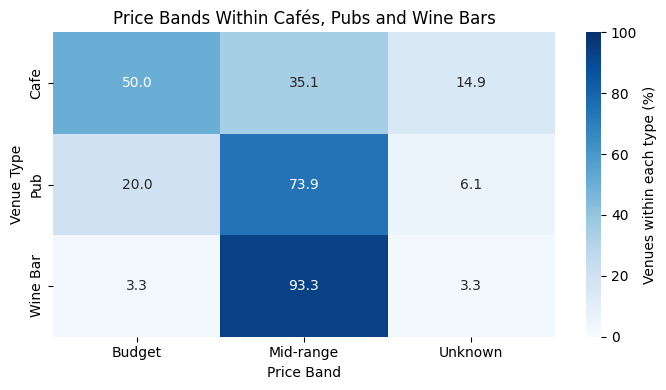

In [47]:
plt.figure(figsize=(7, 4))

sns.heatmap(
    venue_percentages,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Venues within each type (%)"}
)

plt.title("Price Bands Within Cafés, Pubs and Wine Bars")
plt.xlabel("Price Band")
plt.ylabel("Venue Type")
plt.tight_layout()
plt.show()

Key takeaway

Cafés are more budget-oriented (50%), while pubs (73.9%) and wine bars (93.3%) are mainly mid-range. Pricing comparisons should therefore consider venue type.

Wine bars have only 30 listings, and 14.9% of café prices are unknown. Venue groups can overlap.

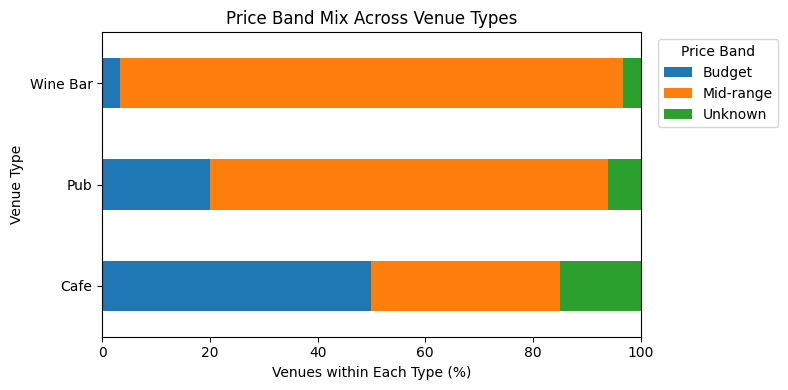

In [48]:
venue_percentages.plot(
    kind="barh",
    stacked=True,
    figsize=(8, 4)
)

plt.title("Price Band Mix Across Venue Types")
plt.xlabel("Venues within Each Type (%)")
plt.ylabel("Venue Type")
plt.xlim(0, 100)
plt.legend(title="Price Band", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

Key takeaway

Cafés are more budget-oriented (50%), while pubs (73.9%) and wine bars (93.3%) are mainly mid-range. Pricing benchmarks should therefore consider venue type.

Interpret wine bars cautiously because there are only 30 listings; café prices are unknown for 14.9% of records.

No selected venues were labelled Expensive. Missing prices 'Unknown label', overlapping groups and the small wine-bar sample (30) limit the comparison.

## Question 5. What do customers mention about food, service and value in review excerpts, and how do these themes differ between higher- and lower-rated restaurants?
Mentions of food, service and value in customer review excerpts may add context beyond average ratings.

First, I will inspect the review excerpts before choosing keyword-matching rules.

In [49]:
# Keep restaurants with a rating and review excerpts
review_data = edinburgh_clean.dropna(
    subset=["Rating", "Reviews"]
).copy()

# Display five examples in full
print(review_data[["Rating", "Reviews"]].head().to_string(index=False))

 Rating                                                                                            Reviews
    5.0     [['Unforgettable', 'GROUP DINING EXPERIENCE DIFFICULT TO BEAT'], ['01/10/2018', '01/09/2018']]
    5.0 [['The pesto offered with the fresh dough bal...', 'Fabulous meal'], ['01/11/2018', '01/10/2018']]
    5.0                   [['Beautiful Meal!', 'Is this my new favourite?'], ['01/06/2018', '01/05/2018']]
    5.0       [['A must if you are in Edinburgh!', 'Incredible experience'], ['01/08/2018', '01/06/2018']]
    5.0                      [['Wonderful', 'We saved the best until last'], ['01/11/2018', '01/10/2018']]


Each entry contains two parts: review excerpts first, then dates. We’ll extract the first part so dates are excluded from keyword matching.

In [50]:
# Exclude records containing no review excerpts
review_data = review_data[
    ~review_data["Reviews"].str.startswith("[[],")
].copy()

### Empty review records

Five records contained empty review lists and were excluded from the text analysis. This left 1,755 restaurants: 1,309 higher-rated and 446 lower-rated. The overall findings were unchanged.


In [51]:
# Extract the section containing review text
review_data["Review Text"] = (
    review_data["Reviews"].str.split("], [", regex=False).str[0]
)

# Use lowercase so matching ignores capitalisation
review_data["Review Text"] = review_data["Review Text"].str.lower()

# Check the extracted text
print(review_data["Review Text"].head().to_string(index=False))

[['unforgettable', 'group dining experience dif...
[['the pesto offered with the fresh dough bal.....
  [['beautiful meal!', 'is this my new favourite?'
[['a must if you are in edinburgh!', 'incredibl...
     [['wonderful', 'we saved the best until last'


regex=False treats "], [" as an exact separator. The original Reviews column stays unchanged.

Some excerpts are shortened with ..., so our findings will describe mentions in the available text, not complete customer feedback.

In [52]:
# Starting keywords for each theme - This is where I will define a small starting list of keywords/These are initial matching rules:
theme_keywords = {
    "Food": ["food", "meal", "dish", "delicious", "tasty"],
    "Service": ["service", "staff", "friendly", "helpful", "waiter", "waitress"],
    "Value": ["value", "price", "cheap", "expensive", "affordable"]
}

True means at least one keyword matched; False means none matched.

| means or, while \b matches word boundaries—for example, "meal" won’t match "mealworm".

Each theme is counted once per restaurant, regardless of repeated mentions.

In [53]:
# Match whole keywords and store True or False for each theme
for theme, words in theme_keywords.items():
    pattern = r"\b(?:" + "|".join(words) + r")\b"

    review_data[theme] = review_data["Review Text"].str.contains(
        pattern, na=False
    )

# Check the first five results
review_data[["Review Text", "Food", "Service", "Value"]].head()

,Review Text,Food,Service,Value
0,"[['unforgettable', 'group dining experience di...",False,False,False
1,[['the pesto offered with the fresh dough bal....,True,False,False
2,"[['beautiful meal!', 'is this my new favourite?'",True,False,False
3,"[['a must if you are in edinburgh!', 'incredib...",False,False,False
4,"[['wonderful', 'we saved the best until last'",False,False,False


The flags look consistent: “meal” matches Food, while “wonderful” alone does not identify a theme.

Before comparing rating groups, I am going to inspect a few matched excerpts: This helps us check that the keywords capture relevant mentions. False means no chosen keyword matched—not that the customer had no opinion about that theme.

In [54]:
# Show examples where a service keyword matched
service_matches = review_data[review_data["Service"]]

print(service_matches["Review Text"].head().to_string(index=False))

[['lovely food and such lovely staff', 'the bes...
[['great service', 'delicious indian meal, reco...
[['lovely food, excellent service!', 'hogmanay ...
[['our favourite restaurant in edinburgh', 'exc...
      [['great food & service', 'fantastic again!'


These examples contain relevant service mentions. However, .head() shows the first matches, which may favour highly rated restaurants.

Let’s check a small random sample in full:

In [55]:
# Inspect five matched excerpts from across the dataset
print(
    service_matches[["Rating", "Review Text"]]
    .sample(5, random_state=42)
    .to_string(index=False)
)

 Rating                                                                Review Text
    4.5                              [['stopped for a drink', 'excellent service!'
    3.5                        [['informal restaurant', 'not the greatest service'
    4.0 [['indeed yummy and great value', 'feiendly and dog friendly turkish cafe'
    3.0      [['visited as a group, not great service.', 'standard franchise food'
    4.5  [['surprised by this culinary hideaway', 'great food and fantastic staff'


These matches are relevant. They include both praise and criticism, confirming that we are identifying service mentions, not sentiment. 

“Dog friendly” also shows why context matters—it does not necessarily describe staff.

Note! Keyword-matching limitations : Spelling errors, unlisted synonyms and shortened excerpts may cause missed matches. Context can also produce misleading matches, such as “dog friendly” under Service. Results describe selected keyword mentions, not a complete assessment of customer opinions.

In [56]:
# Define two clear rating groups
# Create a separate table for comparing higher and lower ratings
theme_comparison = review_data.copy()

theme_comparison["Rating Group"] = "Lower (1–3.5)"

theme_comparison.loc[
    theme_comparison["Rating"] >= 4,
    "Rating Group"
] = "Higher (4–5)"

# Check the number of restaurants in each group
theme_comparison["Rating Group"].value_counts()

Rating Group
Higher (4–5)     1309
Lower (1–3.5)     446
Name: count, dtype: int64

For this exploratory comparison, ratings of 4–5 are grouped as higher and 1–3.5 as lower. Keyword matches indicate theme mentions, not positive or negative opinions.

The groups contain 1,309 higher-rated and 446 lower-rated restaurants. We’ll compare percentages because the group sizes differ.

In [57]:
# Percentage of restaurants mentioning each theme
theme_percentages = (
    theme_comparison.groupby("Rating Group")[["Food", "Service", "Value"]]
    .mean() * 100
) #For True/False columns, .mean() calculates the proportion marked True. Multiplying by 100 gives the percentage.

theme_percentages.round(1)

,Food,Service,Value
Rating Group,,,
Higher (4–5),37.9,16.2,5.1
Lower (1–3.5),28.9,15.2,9.2


The results show:
- Food: mentioned more often in higher-rated restaurants’ excerpts (37.9% vs 28.9%).
- Service: similar mention rates (16.2% vs 15.2%).
- Value: mentioned more often in lower-rated restaurants’ excerpts (9.2% vs 5.1%).
These are mentions, not praise or complaints. We should inspect value matches before interpreting why they differ.

A grouped bar chart will show the comparison clearly:

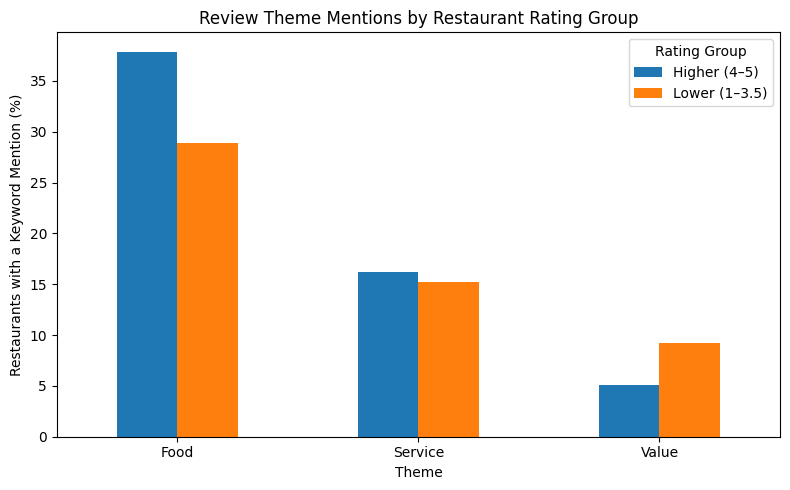

In [58]:
theme_percentages.T.plot(kind="bar", figsize=(8, 5))

plt.title("Review Theme Mentions by Restaurant Rating Group")
plt.xlabel("Theme")
plt.ylabel("Restaurants with a Keyword Mention (%)")
plt.xticks(rotation=0)
plt.legend(title="Rating Group")
plt.tight_layout()
plt.show()

Key takeaway

Food is mentioned more often in higher-rated restaurants’ excerpts (37.9% vs 28.9%), while value appears more often in lower-rated restaurants’ excerpts (9.2% vs 5.1%). Service mentions are similar.

Value-related excerpts warrant closer reading before drawing pricing conclusions. Keyword matches identify mentions, not praise or complaints, and may miss spelling errors or shortened text.

## 5. Data Visualisations

The charts below bring together our five analytical questions and add context on review counts, ranking extremes and the overall rating distribution. Cuisine and venue groups can overlap.

### Review-count distribution

Known review counts only. Logarithmic intervals show the full range without removing restaurants with very high counts.

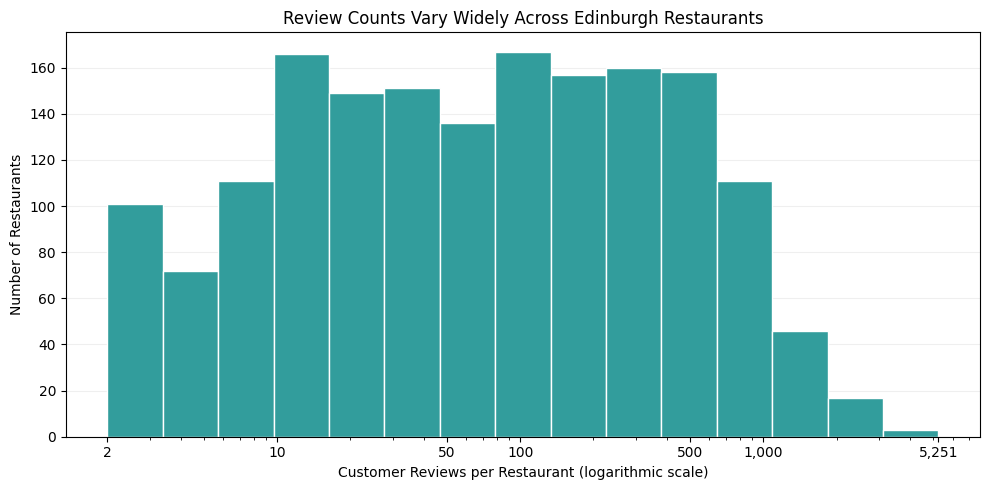

In [59]:
review_counts = edinburgh_clean["Number of Reviews"].dropna()

# Equal-width intervals on a logarithmic scale
bins = np.geomspace(review_counts.min(), review_counts.max(), 16)

plt.figure(figsize=(10, 5))

plt.hist(
    review_counts,
    bins=bins,
    color="#329D9C",
    edgecolor="white"
)

plt.xscale("log")
plt.xticks(
    [2, 10, 50, 100, 500, 1000, 5251],
    ["2", "10", "50", "100", "500", "1,000", "5,251"]
)

plt.title("Review Counts Vary Widely Across Edinburgh Restaurants")
plt.xlabel("Customer Reviews per Restaurant (logarithmic scale)")
plt.ylabel("Number of Restaurants")
plt.grid(axis="y", alpha=0.2)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()

**Takeaway:** Review counts vary widely, so customer ratings should be considered alongside the amount of feedback available.

### Cuisine ratings and supporting evidence

Bubble size represents the number of rated restaurants. Each point summarises one cuisine; the displayed rating range is 3–5.

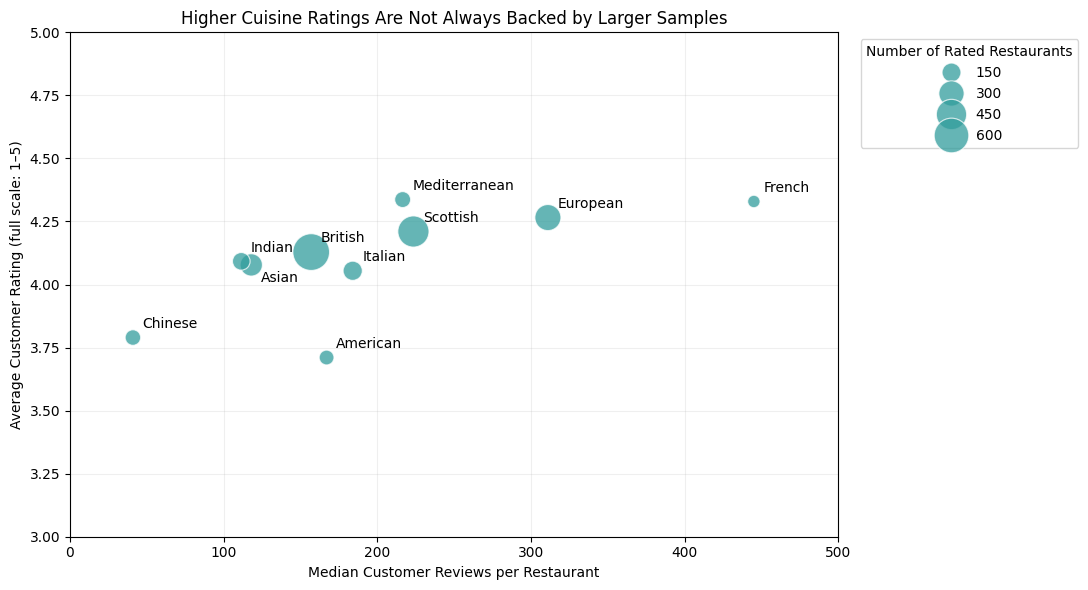

In [60]:
plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=cuisine_summary,
    x="median_reviews",
    y="mean_rating",
    size="rated_restaurants",
    sizes=(80, 700),
    color="#329D9C",
    alpha=0.75,
    edgecolor="white"
)

for cuisine, row in cuisine_summary.iterrows():
    # Separate the two closest labels
    offset = (7, -12) if cuisine == "Asian" else (7, 7)

    plt.annotate(
        cuisine,
        (row["median_reviews"], row["mean_rating"]),
        xytext=offset,
        textcoords="offset points",
        fontsize=10
    )

plt.xlim(0, 500)
plt.ylim(3, 5)

plt.title("Higher Cuisine Ratings Are Not Always Backed by Larger Samples")
plt.xlabel("Median Customer Reviews per Restaurant")
plt.ylabel("Average Customer Rating (full scale: 1–5)")
plt.legend(
    title="Number of Rated Restaurants",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.2)
plt.gca().set_axisbelow(True)
plt.tight_layout()
plt.show()

**Takeaway:** French and Mediterranean have strong average ratings but smaller restaurant samples than British and Scottish cuisines. Bubble size provides context, not statistical certainty.

### Refreshed EDA charts

These charts revisit Questions 1–5 using the same data and comparisons. Colours distinguish groups where needed; Unknown prices remain grey. Counts describe available records, and cuisine and venue groups can overlap.


In [61]:
# Consistent formatting for the charts below
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "grid.alpha": 0.2,
    "axes.spines.top": False,
    "axes.spines.right": False
})
price_colours = {"Budget": "#329D9C", "Mid-range": "#547DB8",
                 "Expensive": "#A575A8", "Unknown": "#B8BEC7"}


### 1. Ratings by price band

Known prices and ratings only. Boxes show the middle 50% of ratings; centre lines show medians. Group sizes are shown below each price band.


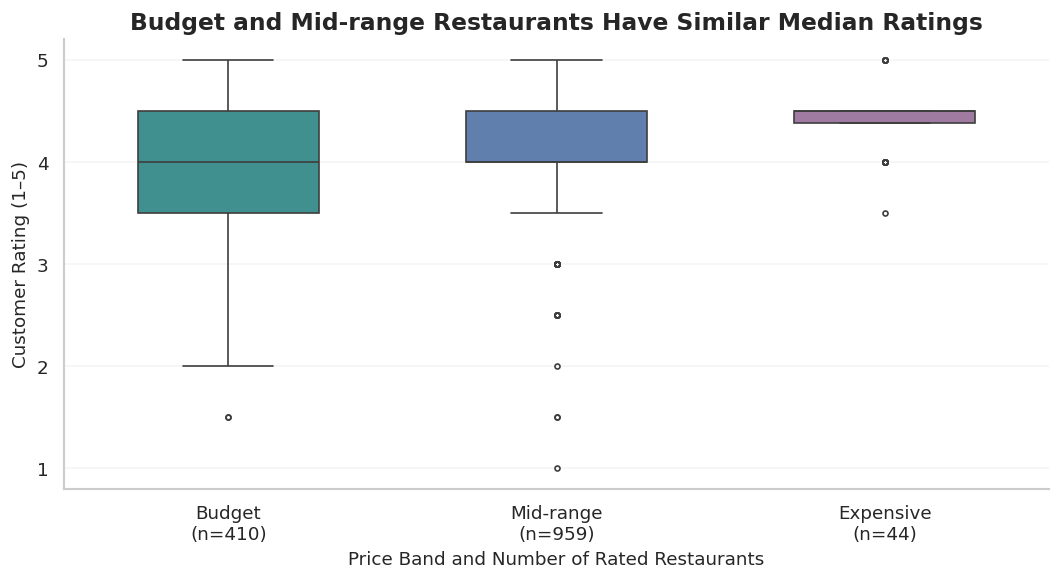

In [62]:
order = ["Budget", "Mid-range", "Expensive"]
plt.figure(figsize=(9, 5))
sns.boxplot(data=price_comparison, x="Price Range", y="Rating",
            order=order, hue="Price Range", palette=price_colours,
            dodge=False, legend=False, width=0.55, fliersize=3)
counts = price_comparison.groupby("Price Range")["Rating"].count()
plt.xticks(range(3), [f"{p}\n(n={counts[p]:,})" for p in order])
plt.ylim(0.8, 5.2)
plt.yticks([1, 2, 3, 4, 5])
plt.title("Budget and Mid-range Restaurants Have Similar Median Ratings")
plt.xlabel("Price Band and Number of Rated Restaurants")
plt.ylabel("Customer Rating (1–5)")
plt.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()


**Takeaway:** Budget and Mid-range have the same median rating. The Expensive group scores higher but contains only 44 rated restaurants.

### 2. Average ratings across cuisines

Labels show the average rating and number of rated restaurants. Overlapping cuisine categories are not independent groups.


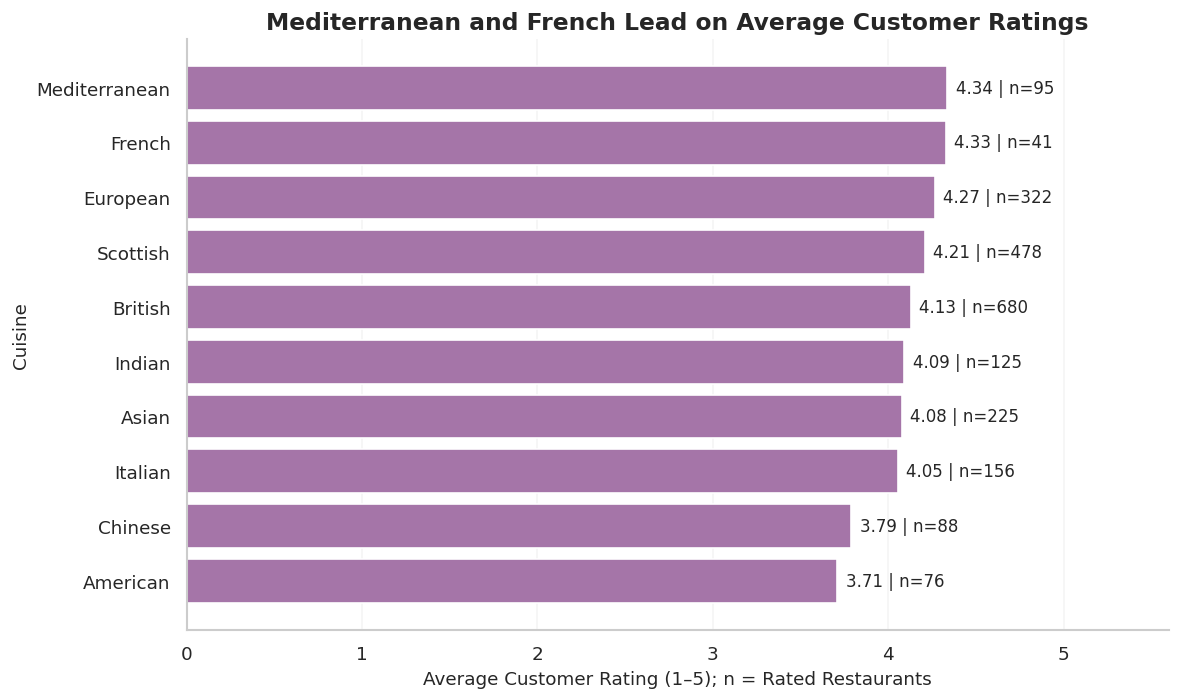

In [63]:
chart_data = cuisine_summary.sort_values("mean_rating")
plt.figure(figsize=(10, 6))
bars = plt.barh(chart_data.index, chart_data["mean_rating"], color="#A575A8")
plt.bar_label(bars, labels=[f"{r.mean_rating:.2f} | n={int(r.rated_restaurants):,}"
              for r in chart_data.itertuples()], padding=5, fontsize=10)
plt.xlim(0, 5.6)
plt.xticks([0, 1, 2, 3, 4, 5])
plt.title("Mediterranean and French Lead on Average Customer Ratings")
plt.xlabel("Average Customer Rating (1–5); n = Rated Restaurants")
plt.ylabel("Cuisine")
plt.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()


**Takeaway:** Mediterranean and French lead on average ratings, while European and Scottish provide larger comparison groups.

### 3. Cuisine ratings and review counts

Each point represents one cuisine. Ratings use a focused 3–5 display range; the full rating scale is 1–5.


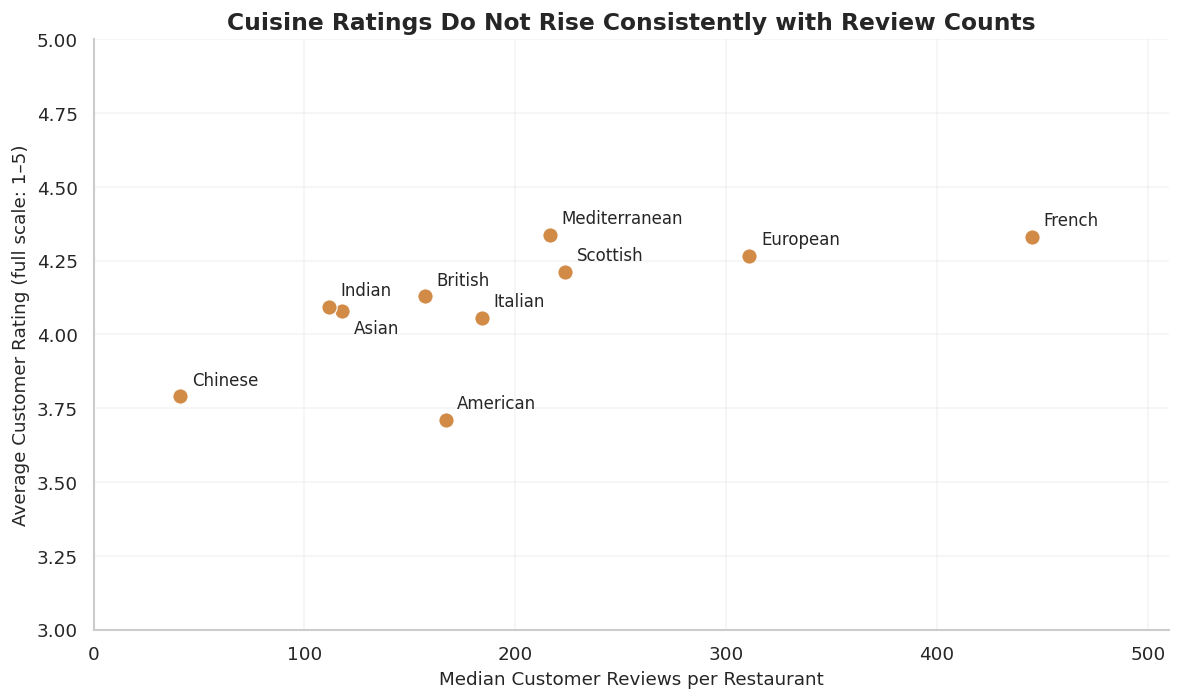

In [64]:
plt.figure(figsize=(10, 6))
plt.scatter(cuisine_summary["median_reviews"], cuisine_summary["mean_rating"],
            s=85, color="#D18B47", edgecolor="white", linewidth=0.7)
for cuisine, row in cuisine_summary.iterrows():
    offset = (7, -13) if cuisine == "Asian" else (7, 7)
    plt.annotate(cuisine, (row["median_reviews"], row["mean_rating"]),
                 xytext=offset, textcoords="offset points", fontsize=10)
plt.xlim(0, 510)
plt.ylim(3, 5)
plt.title("Cuisine Ratings Do Not Rise Consistently with Review Counts")
plt.xlabel("Median Customer Reviews per Restaurant")
plt.ylabel("Average Customer Rating (full scale: 1–5)")
plt.tight_layout()
plt.show()


**Takeaway:** French has the highest median review count, but more reviews do not consistently accompany higher cuisine ratings.

### 4. Rating spread across four cuisines

The four cuisines share a median rating of 4.5. Boxes describe variation, not confidence intervals.


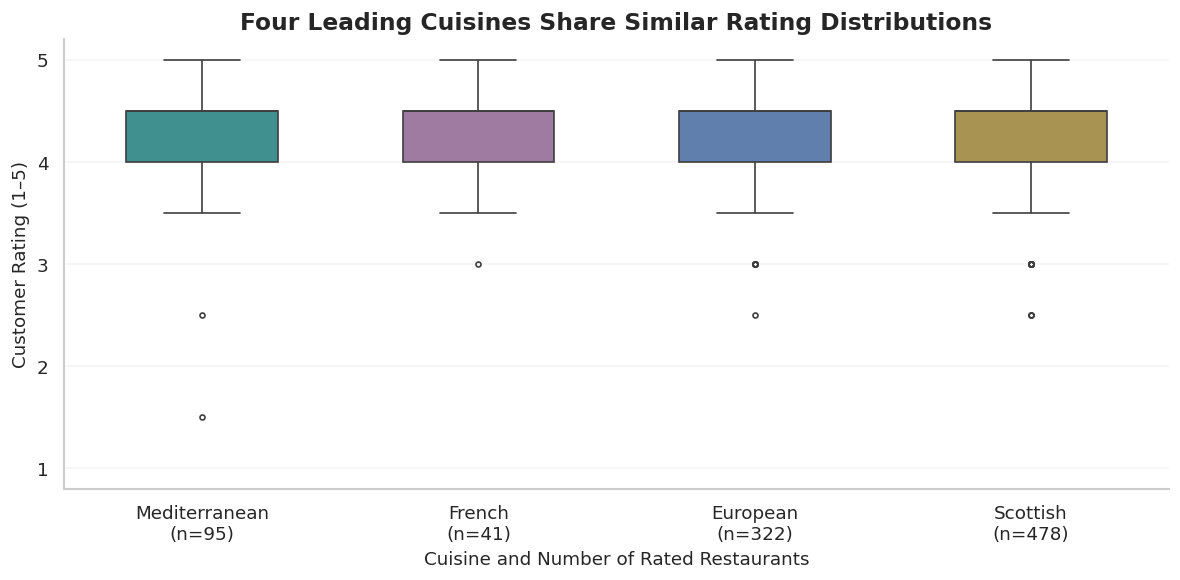

In [65]:
cuisine_plot = cuisine_comparison.reset_index(drop=True)
order = ["Mediterranean", "French", "European", "Scottish"]
colours = dict(zip(order, ["#329D9C", "#A575A8", "#547DB8", "#B89A43"]))
plt.figure(figsize=(10, 5))
sns.boxplot(data=cuisine_plot, x="Cuisine Labels", y="Rating", order=order,
            hue="Cuisine Labels", hue_order=order, palette=colours, legend=False,
            dodge=False, width=0.55, fliersize=3)
counts = cuisine_plot.groupby("Cuisine Labels")["Rating"].count()
plt.xticks(range(4), [f"{c}\n(n={counts[c]:,})" for c in order])
plt.ylim(0.8, 5.2)
plt.yticks([1, 2, 3, 4, 5])
plt.title("Four Leading Cuisines Share Similar Rating Distributions")
plt.xlabel("Cuisine and Number of Rated Restaurants")
plt.ylabel("Customer Rating (1–5)")
plt.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()


**Takeaway:** The four cuisines share a median of 4.5 and similar rating spreads; averages alone do not identify a clear winner.

### 5. Review counts and ranking

Only restaurants rated 4.5 with known rankings and review counts are included. Position 1 is best, so better positions appear at the top.


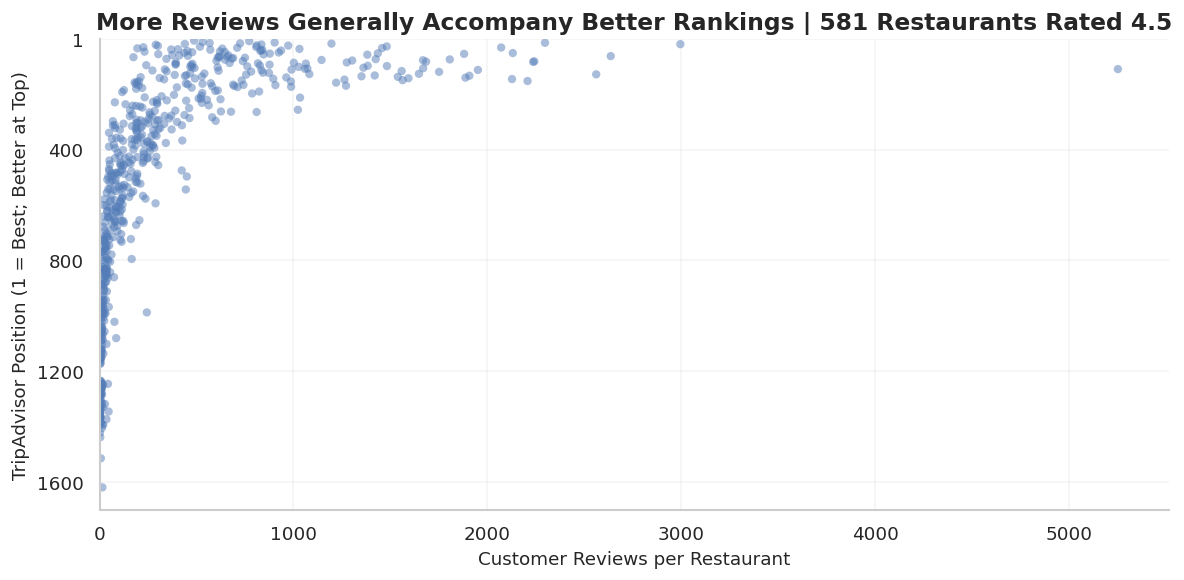

In [66]:
plt.figure(figsize=(10, 5))
plt.scatter(rating_45["Number of Reviews"], rating_45["Ranking"],
            s=25, alpha=0.5, color="#547DB8", edgecolors="none")
plt.xlim(left=0)
plt.ylim(1700, 1)
plt.yticks([1, 400, 800, 1200, 1600])
plt.title(f"More Reviews Generally Accompany Better Rankings | {len(rating_45):,} Restaurants Rated 4.5")
plt.xlabel("Customer Reviews per Restaurant")
plt.ylabel("TripAdvisor Position (1 = Best; Better at Top)")
plt.tight_layout()
plt.show()


**Takeaway:** Among restaurants rated 4.5, higher review counts generally accompany better ranking positions. This does not establish how rankings are calculated.

### 6. Ranking comparison on a logarithmic scale

Only restaurants rated 4.5 with known rankings and review counts are included. Position 1 is best, so better positions appear at the top. Review-count tick labels show actual counts on a logarithmic scale.


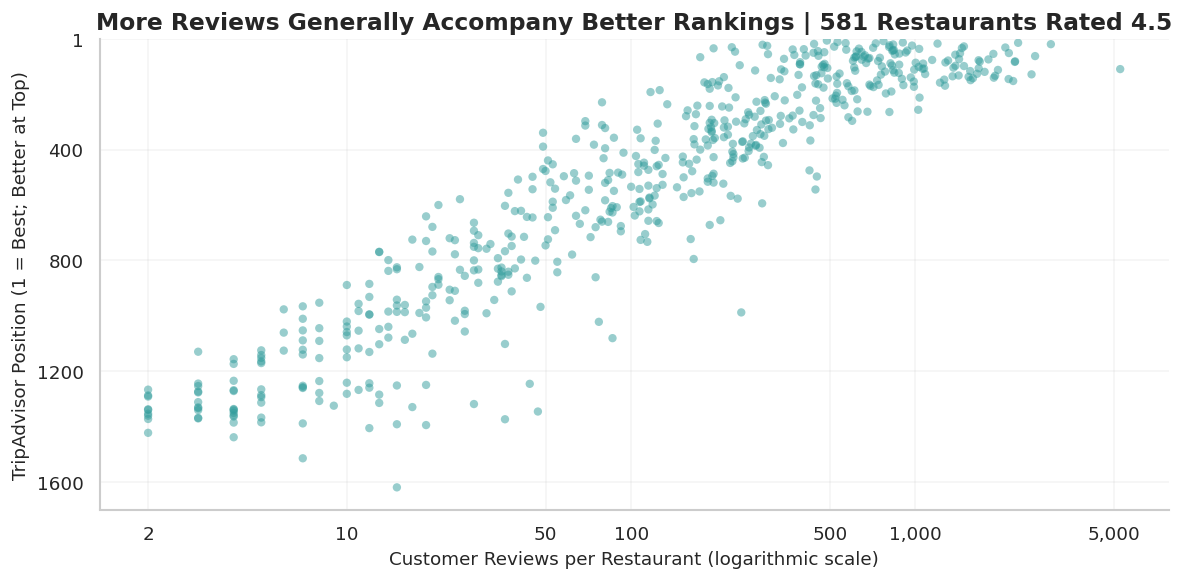

In [67]:
plt.figure(figsize=(10, 5))
plt.scatter(rating_45["Number of Reviews"], rating_45["Ranking"],
            s=25, alpha=0.5, color="#329D9C", edgecolors="none")
plt.xscale("log")
plt.xticks([2, 10, 50, 100, 500, 1000, 5000],
           ["2", "10", "50", "100", "500", "1,000", "5,000"])
plt.ylim(1700, 1)
plt.yticks([1, 400, 800, 1200, 1600])
plt.title(f"More Reviews Generally Accompany Better Rankings | {len(rating_45):,} Restaurants Rated 4.5")
plt.xlabel("Customer Reviews per Restaurant (logarithmic scale)")
plt.ylabel("TripAdvisor Position (1 = Best; Better at Top)")
plt.tight_layout()
plt.show()


**Takeaway:** The logarithmic scale makes restaurants with fewer reviews easier to compare while retaining all 581 records.

### 7. Price bands within venue types

Percentages use all listings in each venue type, including Unknown prices. No selected venues are labelled Expensive. Venue labels can overlap.


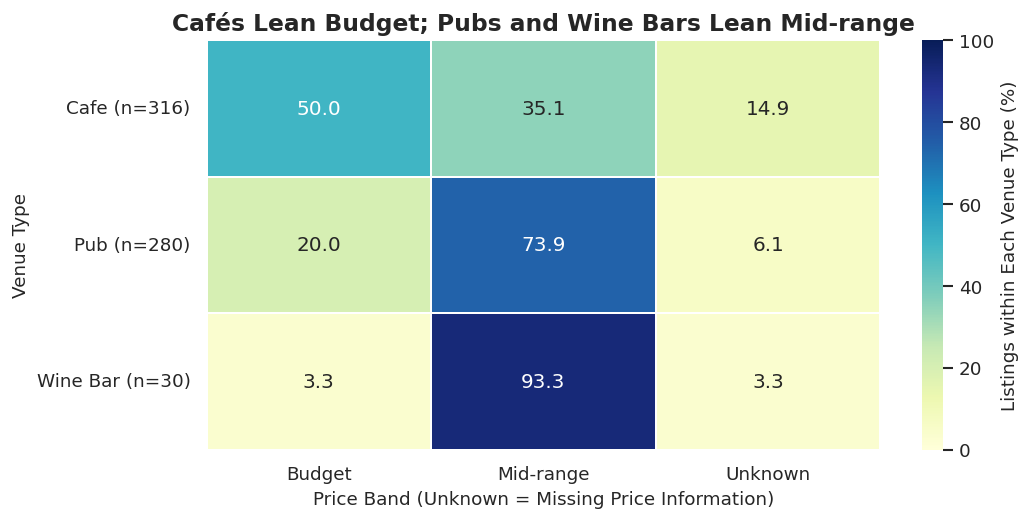

In [68]:
venue_plot = venue_percentages.reindex(["Cafe", "Pub", "Wine Bar"])
counts = venue_data["Cuisine Labels"].value_counts()
plt.figure(figsize=(9, 4.5))
sns.heatmap(venue_plot, annot=True, fmt=".1f", cmap="YlGnBu",
            vmin=0, vmax=100, linewidths=1, linecolor="white",
            cbar_kws={"label": "Listings within Each Venue Type (%)"})
plt.yticks([0.5, 1.5, 2.5], [f"{v} (n={counts[v]:,})" for v in venue_plot.index], rotation=0)
plt.title("Cafés Lean Budget; Pubs and Wine Bars Lean Mid-range")
plt.xlabel("Price Band (Unknown = Missing Price Information)")
plt.ylabel("Venue Type")
plt.tight_layout()
plt.show()


**Takeaway:** Cafés are more budget-oriented; pubs and wine bars are mainly Mid-range. Unknown prices remain visible.

### 8. Comparing the price mix

The same percentages are shown as 100% stacked bars. Grey marks missing price information, not an additional spending tier.


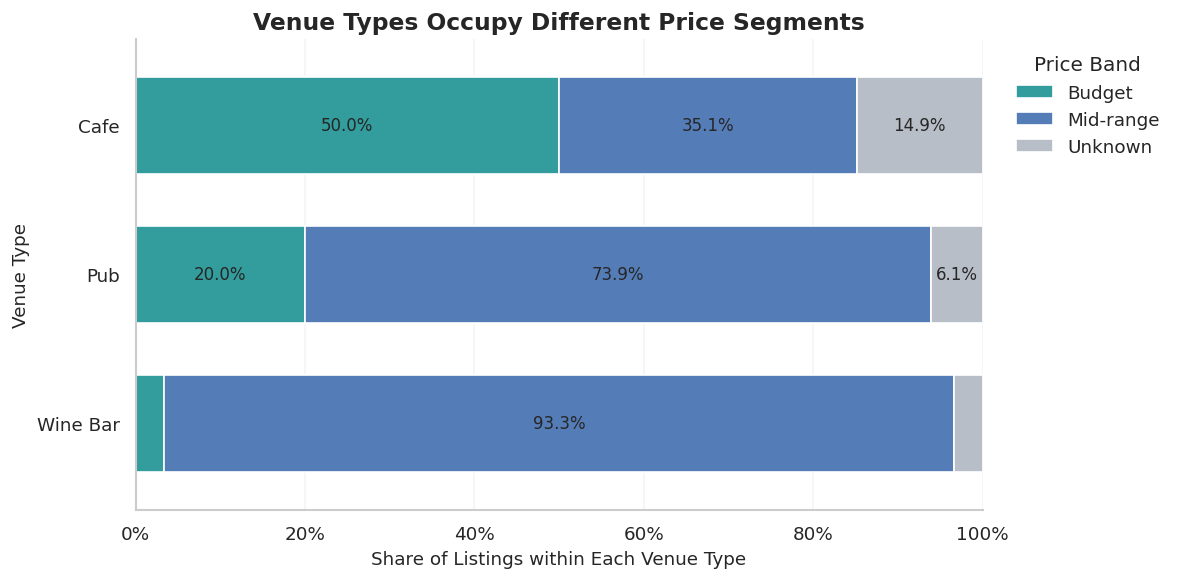

In [69]:
venue_plot = venue_percentages.reindex(["Cafe", "Pub", "Wine Bar"])
ax = venue_plot.plot(kind="barh", stacked=True, figsize=(10, 5),
                     color=[price_colours[c] for c in venue_plot.columns],
                     edgecolor="white", width=0.65)
for container in ax.containers:
    ax.bar_label(container, labels=[f"{v:.1f}%" if v >= 6 else "" for v in container.datavalues],
                 label_type="center", fontsize=10)
ax.invert_yaxis()
plt.xlim(0, 100)
plt.xticks([0, 20, 40, 60, 80, 100], ["0%", "20%", "40%", "60%", "80%", "100%"])
plt.title("Venue Types Occupy Different Price Segments")
plt.xlabel("Share of Listings within Each Venue Type")
plt.ylabel("Venue Type")
plt.legend(title="Price Band", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()


**Takeaway:** Compare prices within similar venue types. Wine bars have a smaller sample, and missing prices are most common among cafés.

### 9. Review themes by rating group

Each percentage is the share of restaurants with at least one matching keyword in their available excerpts. Mentions can be positive or negative, and themes can overlap.


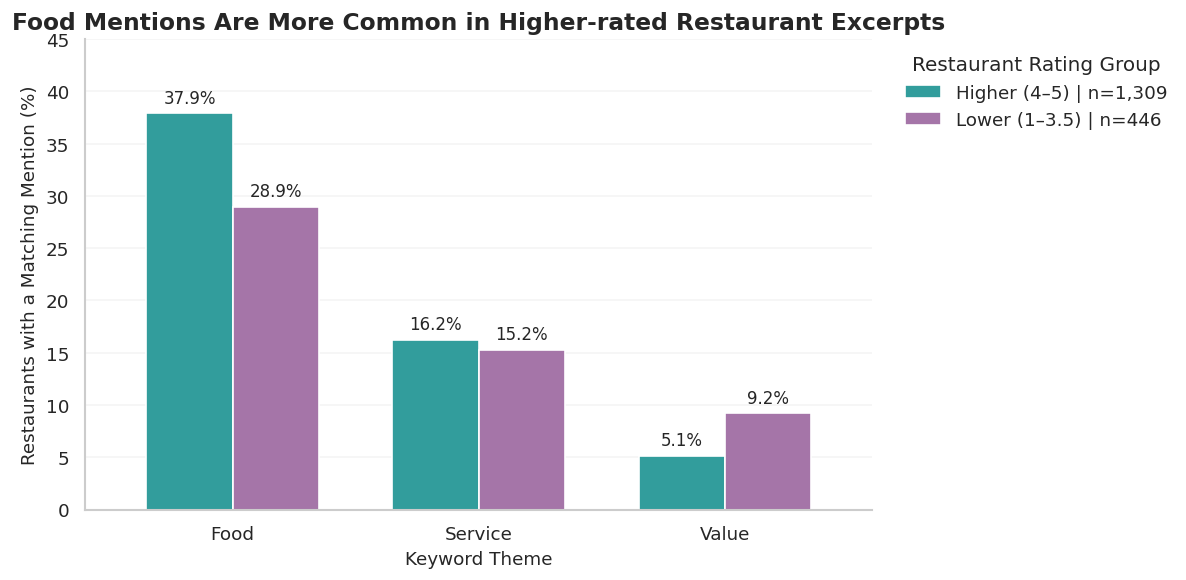

In [70]:
theme_plot = theme_percentages.reindex(["Higher (4–5)", "Lower (1–3.5)"]).T
ax = theme_plot.plot(kind="bar", figsize=(10, 5), color=["#329D9C", "#A575A8"],
                     edgecolor="white", width=0.7)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=4, fontsize=10)
plt.ylim(0, 45)
plt.xticks(rotation=0)
plt.title("Food Mentions Are More Common in Higher-rated Restaurant Excerpts")
plt.xlabel("Keyword Theme")
plt.ylabel("Restaurants with a Matching Mention (%)")
counts = theme_comparison["Rating Group"].value_counts()
plt.legend(title="Restaurant Rating Group", labels=[f"{g} | n={counts[g]:,}" for g in theme_plot.columns],
           bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()


**Takeaway:** Food mentions are more common in higher-rated listings; value mentions are more common in lower-rated listings. Mentions do not establish sentiment.

### Highest- and lowest-ranked restaurants

The 10 highest and 10 lowest available TripAdvisor positions select the restaurants; bar lengths show customer ratings. These rankings do not measure financial performance.

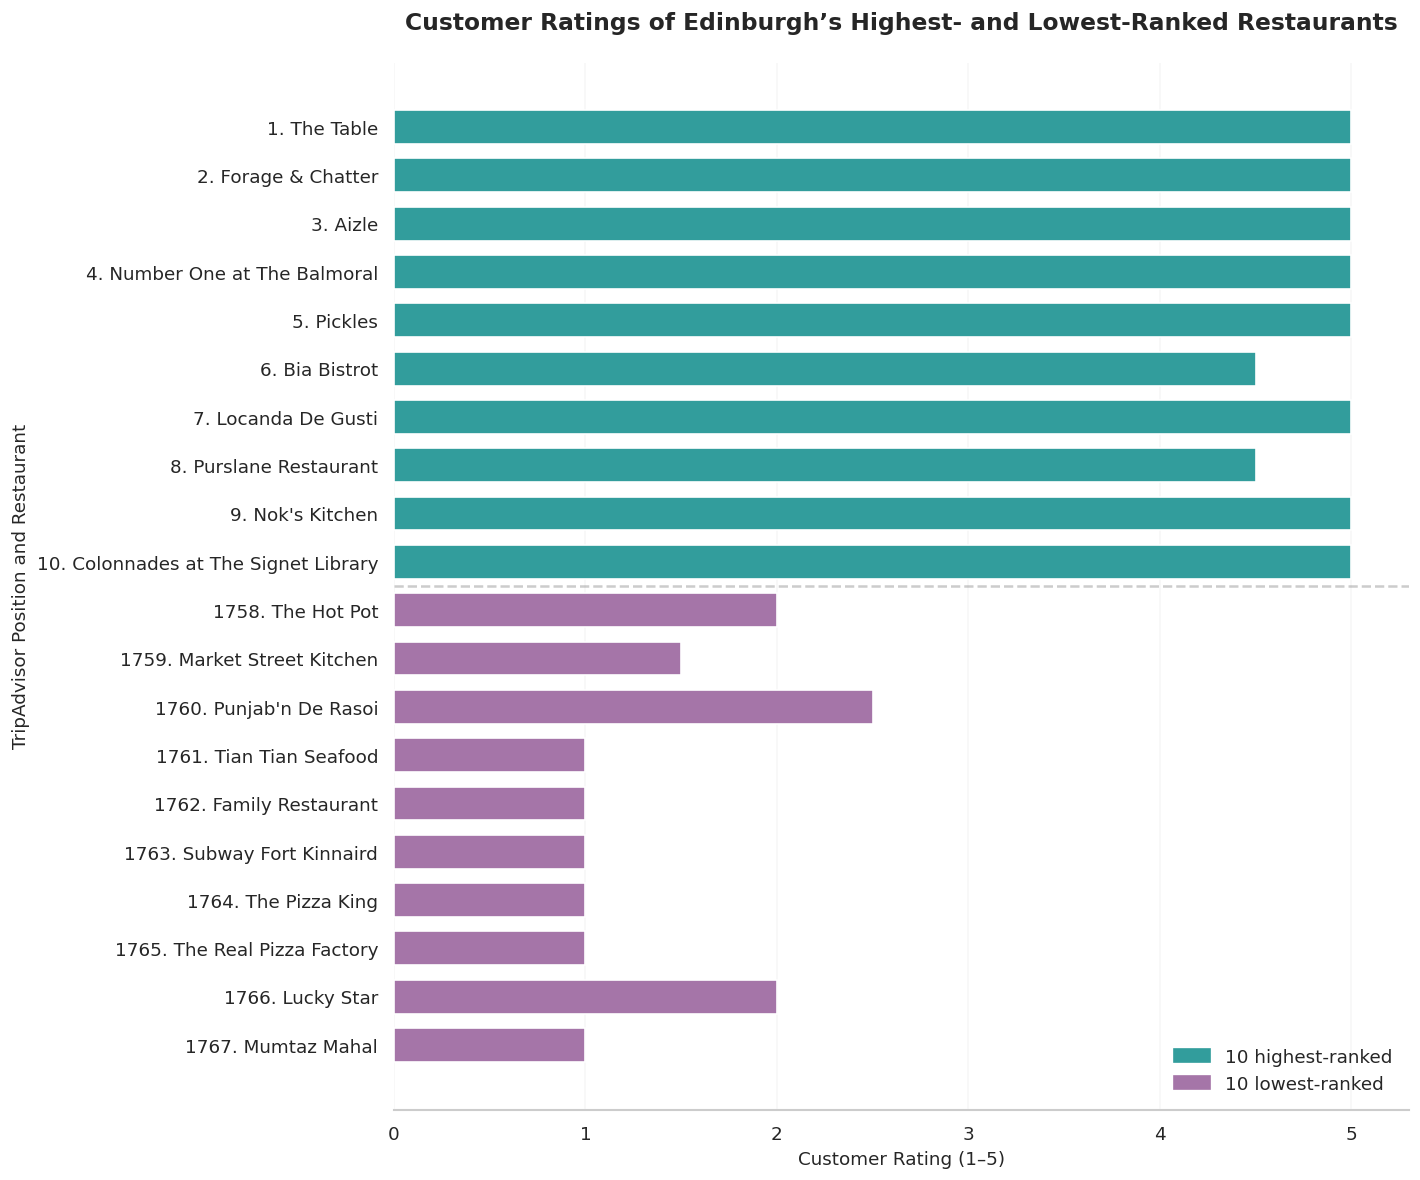

In [71]:
from matplotlib.patches import Patch

ranked = edinburgh_clean.dropna(subset=["Ranking", "Rating"]).sort_values("Ranking")
comparison = pd.concat([ranked.head(10), ranked.tail(10)])
labels = comparison["Ranking"].astype(str) + ". " + comparison["Name"]
colours = ["#329D9C"] * 10 + ["#A575A8"] * 10

fig, ax = plt.subplots(figsize=(12, 10))
ax.barh(labels, comparison["Rating"], color=colours, height=0.7)
ax.invert_yaxis()
ax.axhline(9.5, color="grey", linestyle="--", alpha=0.4)
ax.set_title("Customer Ratings of Edinburgh’s Highest- and Lowest-Ranked Restaurants",
             fontsize=14, fontweight="bold", pad=20)
ax.set_xlabel("Customer Rating (1–5)")
ax.set_ylabel("TripAdvisor Position and Restaurant")
ax.set_xlim(0, 5.3)
ax.set_xticks([0, 1, 2, 3, 4, 5])
ax.legend(handles=[Patch(color="#329D9C", label="10 highest-ranked"),
                   Patch(color="#A575A8", label="10 lowest-ranked")],
          loc="lower right", frameon=False)
ax.grid(axis="x", alpha=0.15)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()


**Takeaway:** The highest-ranked listings receive strong customer ratings. This is a selected comparison of ranking extremes, rather than a representative picture of all restaurants.

### Customer rating distribution

All restaurants with a recorded rating are included; missing ratings are excluded.

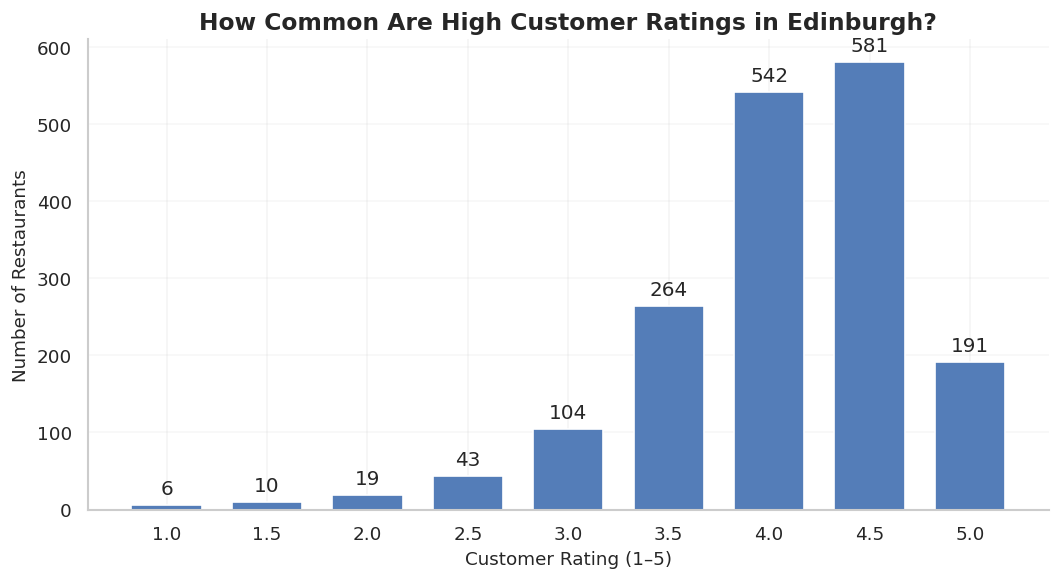

In [72]:
# Count restaurants at each rating
rating_counts = (
    edinburgh_clean["Rating"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(9, 5))

bars = plt.bar(
    rating_counts.index,
    rating_counts.values,
    width=0.35,
    color="#547DB8"
)

plt.bar_label(bars, padding=4)
plt.xticks([1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5])

plt.title("How Common Are High Customer Ratings in Edinburgh?")
plt.xlabel("Customer Rating (1–5)")
plt.ylabel("Number of Restaurants")
plt.grid(axis="y", alpha=0.15)
plt.gca().set_axisbelow(True)
sns.despine()
plt.tight_layout()
plt.show()
 
#**Purpose:** Show how ratings are distributed across all restaurants with a known rating, providing context for our competitor comparisons. Missing ratings are excluded.

**Takeaway:** Ratings of 4.0 and 4.5 are the most common. High ratings are widespread, so review counts and relevant competitor comparisons add useful context.

**Chart references:** [Matplotlib](https://matplotlib.org/stable/api/pyplot_summary.html), [Seaborn boxplot](https://seaborn.pydata.org/generated/seaborn.boxplot.html), [Seaborn heatmap](https://seaborn.pydata.org/generated/seaborn.heatmap.html).

## 6. Final Summary

Across **1,865 Edinburgh restaurant listings**, we explored what customer feedback could tell us about pricing and menu choices.

### Key findings and actions

| Finding | Recommended action |
|---|---|
| Budget and Mid-range average ratings were almost identical: **4.07 and 4.09**. The Expensive group averaged **4.44**, based on 44 rated restaurants. | Avoid assuming a higher price will improve customer satisfaction. |
| Mediterranean and French led on average ratings, but overlapped with European and Scottish cuisines. | Shortlist these cuisines for menu research; no clear winner emerged. |
| Among **581 restaurants rated 4.5**, more reviews generally accompanied better ranking positions. | Compare ratings alongside review counts when assessing competitors. |
| **50% of cafés** were Budget; **73.9% of pubs** and **93.3% of wine bars** were Mid-range. | Benchmark prices against similar venue types. |
| Food mentions were more common in higher-rated listings; value mentions were more common in lower-rated listings. | Read value-related feedback before deciding whether prices need changing. |

### Patterns and unexpected results

Venue types showed distinct pricing patterns, while cuisine ratings overlapped considerably. Identical customer ratings also accompanied very different ranking positions. These are patterns within a snapshot, not trends over time.

### Scope and decisions

Missing numerical values were retained rather than estimated; missing price and cuisine labels became Unknown. Comparisons use available records, overlapping labels and differing sample sizes. Five empty review records were excluded. Keyword mentions describe themes, not positive or negative sentiment, and can miss spelling errors or shortened text.

This historical dataset cannot establish current demand, profitability or cause and effect.

### Final takeaway

**Use comparable competitors to guide pricing and customer feedback to guide menu research.** The project provides starting points for decisions; validate them against current demand, customer preferences and operating costs before making changes.


## Appendix: About the Dataset

### Context and source

The dataset was collected by scraping restaurant listings from **TripAdvisor** across 31 European cities. Individual city datasets were cleaned and combined by the dataset creator.

The Python scraper uses **Pandas** and **BeautifulSoup**.

- [Dataset on Kaggle](https://www.kaggle.com/datasets/damienbeneschi/krakow-ta-restaurans-data-raw)

**Coverage limitation:** Only restaurants listed on TripAdvisor are included. The dataset does not represent every restaurant in each city.

### Content

The dataset covers Amsterdam, Athens, Barcelona, Berlin, Bratislava, Brussels, Budapest, Copenhagen, Dublin, Edinburgh, Geneva, Helsinki, Hamburg, Krakow, Lisbon, Ljubljana, London, Luxembourg, Madrid, Lyon, Milan, Munich, Porto, Oslo, Paris, Prague, Rome, Stockholm, Vienna, Warsaw and Zurich.

The source description reports **125,433 restaurant records**. The supplied CSV contains **34,544 rows**, including **1,865 Edinburgh listings**; source descriptions and distributed file versions differ.

### Data dictionary

| Column | Description |
|---|---|
| **Name** | Restaurant name. |
| **City** | City where the restaurant is located. |
| **Cuisine Style** | Listed cuisines, dietary options and venue types. Stored as text representing a list in the CSV. |
| **Ranking** | Restaurant's TripAdvisor ranking within its city. A smaller number indicates a better position. |
| **Rating** | Overall customer rating, from 1 to 5. |
| **Price Range** | Price category: `$`, `$$ - $$$` or `$$$$`. These are categories, not exact menu prices. |
| **Number of Reviews** | Recorded number of customer reviews. |
| **Reviews** | Up to two displayed review excerpts and their dates. These are not the restaurant's full review history. |
| **URL_TA** | Restaurant page path, following `www.tripadvisor.com`. |
| **ID_TA** | TripAdvisor restaurant identifier. |

Missing information is represented by `NaN`. A missing value does not necessarily mean zero or that the information does not exist.

### Changes made for this project

- Selected Edinburgh restaurants and reset the row index.
- Removed the exported `Unnamed: 0` column.
- Checked for duplicate rows and restaurant IDs; none were found.
- Converted Ranking and Number of Reviews to nullable whole-number types.
- Retained missing numerical values rather than estimating them.
- Labelled missing prices and cuisines as **Unknown**.
- Renamed price categories **Budget**, **Mid-range** and **Expensive**.
- Created **Cuisine Labels** for comparisons across overlapping categories.
- Excluded five empty review-excerpt records from the keyword analysis.

### Interpretation

This is a historical snapshot of listed restaurants. Ratings, review counts and rankings may have changed since collection. Findings support further investigation rather than claims about the whole Edinburgh market.